# 03 Indigent registrations

Compare registered indigent households with households that qualify on income.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[2]      # repo root, two levels above this folder
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from src.common.config import load_config
from src.common.pipeline import build

cfg = load_config()
MODE = os.environ.get("DATA_MODE")          # None = use config; "synthetic" = fake
ghs, ies, nfcm = build(MODE, save=False)

C:\Users\mmjmo\Projects\sa-electricity-nonpayment\src\common\pipeline.py:28: UnicodeWarning: 
One or more strings in the dta file could not be decoded using utf-8, and
so the fallback encoding of latin-1 is being used.  This can happen when a file
has been incorrectly encoded by Stata or some other software. You should verify
the string values returned are correct.
  return pd.read_stata(full, convert_categoricals=False)


In [2]:
from src.a_who_pays import indigent

cutoffs = cfg["indigent"]["income_cutoffs_rand"]
cov = indigent.coverage_table(ies, nfcm, cutoffs)
cov

,province,indigent_registered,qualifying_households,cutoff_rand,coverage,gap_households
0,Eastern Cape,368110,4.363785e+05,3000,0.843557,6.826848e+04
1,Free State,172341,1.525374e+05,3000,1.129828,0.000000e+00
2,Gauteng,372101,9.371882e+05,3000,0.397040,5.650872e+05
3,KwaZulu-Natal,1068078,5.617246e+05,3000,1.901427,0.000000e+00
4,Limpopo,174681,3.755759e+05,3000,0.465102,2.008949e+05
5,Mpumalanga,86743,2.457002e+05,3000,0.353044,1.589572e+05
6,North West,122155,3.423909e+05,3000,0.356771,2.202359e+05
7,Northern Cape,74872,6.946724e+04,3000,1.077803,0.000000e+00
8,Western Cape,318562,1.996638e+05,3000,1.595492,0.000000e+00
9,Eastern Cape,368110,7.917101e+05,4500,0.464956,4.236001e+05


In [3]:
# Numbers used in the answers: national totals at each income cut-off
summary = (cov.groupby("cutoff_rand")[["indigent_registered", "qualifying_households", "gap_households"]]
              .sum())
summary["national_coverage_%"] = (summary["indigent_registered"] / summary["qualifying_households"] * 100).round(0)
(summary[["indigent_registered", "qualifying_households", "gap_households"]] / 1e6).round(2).join(
    summary["national_coverage_%"])

,indigent_registered,qualifying_households,gap_households,national_coverage_%
cutoff_rand,,,,
3000,2.76,3.32,1.21,83.0
4500,2.76,6.04,3.29,46.0
6000,2.76,8.37,5.61,33.0


Coverage above 100% means more households are registered than qualify on the income cut-off used. Municipal cut-offs differ, so compare several.

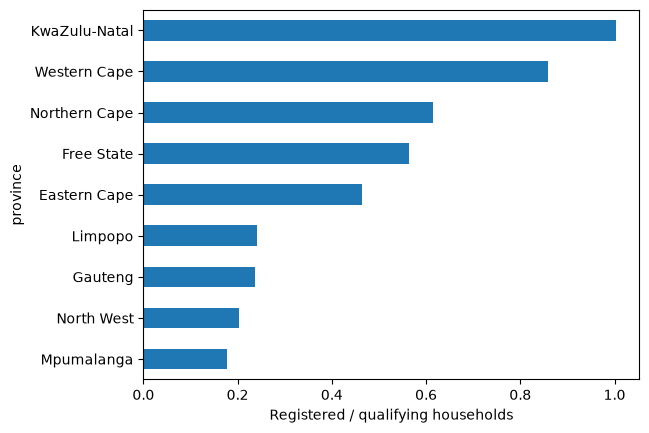

In [4]:
cut = cfg["indigent"]["headline_cutoff_rand"]
headline = cov[cov["cutoff_rand"] == cut].sort_values("coverage")
headline.plot.barh(x="province", y="coverage", legend=False)
plt.xlabel("Registered / qualifying households")
plt.show()

In [5]:
# Province view at the headline cut-off
view = headline.copy()
view["registered_k"] = (view["indigent_registered"] / 1000).round(0)
view["qualifying_k"] = (view["qualifying_households"] / 1000).round(0)
view["coverage_%"] = (view["coverage"] * 100).round(0)
view["gap_k"] = (view["gap_households"] / 1000).round(0)
view[["province", "registered_k", "qualifying_k", "coverage_%", "gap_k"]]

,province,registered_k,qualifying_k,coverage_%,gap_k
14,Mpumalanga,87.0,490.0,18.0,403.0
15,North West,122.0,602.0,20.0,480.0
11,Gauteng,372.0,1571.0,24.0,1199.0
13,Limpopo,175.0,726.0,24.0,552.0
9,Eastern Cape,368.0,792.0,46.0,424.0
10,Free State,172.0,305.0,56.0,133.0
16,Northern Cape,75.0,122.0,61.0,47.0
17,Western Cape,319.0,371.0,86.0,52.0
12,KwaZulu-Natal,1068.0,1065.0,100.0,0.0


### What does coverage mean, and why compare several cut-offs?
Coverage is registered indigent households divided by the households that qualify on income. At a cut-off of R4,500 a month, about 2.76 million households are registered against about 6.04 million that qualify, so national coverage is about 46%. At R3,000 it is about 83% and at R6,000 about 33%. The answer depends heavily on the cut-off, and municipalities set their own, so I show three. Below 100% means some households that qualify on income are not registered. Around 100% means registrations roughly match the number that qualify on that cut-off, which is what we see in KwaZulu-Natal.

In [6]:
# Registered indigent households against households actually receiving free basic electricity
check = nfcm.copy()
check["fbe_to_indigent_ratio"] = (check["fbe_households"] / check["indigent_registered"]).round(2)
check.sort_values("fbe_to_indigent_ratio")

,province,indigent_registered,fbe_households,fbe_to_indigent_ratio
3,KwaZulu-Natal,1068078,323029,0.30
4,Limpopo,174681,68214,0.39
0,Eastern Cape,368110,241557,0.66
5,Mpumalanga,86743,74680,0.86
6,North West,122155,107092,0.88
7,Northern Cape,74872,71484,0.95
2,Gauteng,372101,357414,0.96
1,Free State,172341,171513,1.00
8,Western Cape,318562,434763,1.36


### Which provinces have the lowest coverage?
At R4,500 the lowest coverage is in Mpumalanga (18%), North West (20%), Gauteng and Limpopo (24% each). Gauteng has the largest gap in numbers: about 1.2 million households qualify on income but are not registered. KwaZulu-Natal (about 100%) and the Western Cape (86%) have the highest coverage. I do not know why. Registration is voluntary and may depend on how municipalities run their programmes, so coverage may reflect administration as much as need. In KwaZulu-Natal about 1.07 million households are registered but only about 323,000 receive free basic electricity, so registration does not always mean free electricity.

### Limits 

1. The income cut-offs (R3,000, R4,500, R6,000 a month) are my assumption. Municipalities set their own rules, so I need to check their indigent policies.
2. Households can qualify on other grounds, for example property value, so income alone does not fully define who is eligible.
3. The registered numbers are the municipalities' own counts for 2023, marked with an asterisk in the Stats SA table, and I do not yet know what the asterisk means. The income data is from the 2022/23 IES.
4. The qualifying count includes every household under the cut-off, whether or not it has an electricity connection.